# RoadScan — training sampling pilot
Test a training-only sampling policy: country-balanced random sampling versus country/class-aware sampling with 20% background images. Each arm uses 1,200 unique training images, the same starting checkpoint and four epochs. Keep all development annotations unchanged and never open test labels. This tests a sampling policy, not the individual effects of background control and class balancing. A small single-seed pilot cannot establish deployment quality.


## 1. Verify the saved checkpoint
Continue from notebook 10 selected weights. Verify the saved hash and use the audited training pool from notebook 09. No source labels are edited.


In [1]:
import sys, subprocess, json, shutil, hashlib, time, gc
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
subprocess.run([sys.executable,'-m','pip','install','-q','ultralytics==8.4.177'],check=True,timeout=180)
import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt
from ultralytics import YOLO
from IPython.display import display, Markdown
OUT=Path('/kaggle/working/balance_pilot');OUT.mkdir(exist_ok=True)
AUDIT=Path('/kaggle/input/notebooks/rimasabunasser/09-roadscan-data-diagnosis/diagnosis')
BASE=Path('/kaggle/input/notebooks/rimasabunasser/10-roadscan-freezing-pilot/freeze_pilot')
SOURCE=Path('/kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo')
CLASSES=['D00','D10','D20','D40']
START=BASE/'model_bundle/best.pt'
digests=json.loads((BASE/'model_bundle/SHA256.json').read_text())
assert hashlib.sha256(START.read_bytes()).hexdigest()==digests['best.pt']
assert list(YOLO(str(START)).names.values())==CLASSES
plan=dict(epochs=4,max_gpu_minutes=20,arms={'random':None,'balanced':None},seed=42,images_per_country=400,background_per_country=80,class_target_per_country=80,start_sha256=digests['best.pt'])
(OUT/'plan.json').write_text(json.dumps(plan,indent=2))
print('GPU:',torch.cuda.is_available(),'Starting checkpoint verified.')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 3.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: True Starting checkpoint verified.


## 2. Select and audit equally sized samples
Take 400 unique images per country for both arms. The control is random within each country. The alternative contains 80 backgrounds and 320 damaged images per country; include up to 80 examples of each class before filling the remaining slots. Rare classes with fewer than 80 images retain all available examples. Classes can overlap in an image, so exact class balance is neither possible nor claimed. Save manifests and realized support. Development sets and the 400-image checkpoint-selection monitor remain fixed. Temporary image copies are excluded from saved outputs.


In [2]:
def rebase(p):return str(SOURCE/str(p).split('/RoadScan_yolo/',1)[1])
pool=pd.read_csv(AUDIT/'label_audit.csv')
pool=pool[pool.split=='train'].copy().sort_values('path')
assert len(pool)==11149
samples={'random':[],'balanced':[]}
for country in ['Czech','India','Japan']:
    group=pool[pool.country==country]
    samples['random'].append(group.sample(n=400,random_state=42))
    positive=group[group.boxes>0];negative=group[group.boxes==0]
    selected=set()
    for cls in sorted(CLASSES,key=lambda name:int((positive[name]>0).sum())):
        available=positive[positive[cls]>0]
        selected.update(available.sample(n=min(80,len(available)),random_state=42).index)
    remaining=positive.drop(index=list(selected))
    selected.update(remaining.sample(n=320-len(selected),random_state=42).index)
    samples['balanced'].append(pd.concat([positive.loc[sorted(selected)],negative.sample(n=80,random_state=42)]))
tables={name:pd.concat(parts).sort_values('path').reset_index(drop=True) for name,parts in samples.items()}
for split,filename in [('monitor','monitor_manifest.csv'),('in_domain_dev','in_domain_dev_manifest.csv'),('china_dev','china_dev_manifest.csv')]:tables[split]=pd.read_csv(BASE/filename)
LOCAL=Path('/kaggle/temp/balance_data');YAMLS={};support=[]
for split,table in tables.items():
    table['path']=table.path.map(rebase);table['label']=table.label.map(rebase)
    assert table.path.is_unique
    images=LOCAL/split/'images';labels=LOCAL/split/'labels';images.mkdir(parents=True,exist_ok=True);labels.mkdir(exist_ok=True)
    def copy_pair(row):
        shutil.copy2(row.path,images/Path(row.path).name);shutil.copy2(row.label,labels/Path(row.label).name)
    with ThreadPoolExecutor(max_workers=8) as executor:list(executor.map(copy_pair,table.itertuples()))
    (OUT/(split+'.txt')).write_text('\n'.join(str(images/Path(p).name) for p in table.path))
    table.to_csv(OUT/(split+'_manifest.csv'),index=False)
    print('Cached',split,len(table),flush=True)
for arm in ['random','balanced']:
    assert len(tables[arm])==1200
    assert set(tables[arm].path).isdisjoint(set(tables['in_domain_dev'].path)|set(tables['china_dev'].path))
    for country,group in tables[arm].groupby('country'):
        support.append(dict(arm=arm,country=country,images=len(group),backgrounds=int((group.boxes==0).sum()),**{cls:int((group[cls]>0).sum()) for cls in CLASSES}))
    path=OUT/(arm+'.yaml');path.write_text(yaml.safe_dump(dict(path=str(LOCAL),train=str(OUT/(arm+'.txt')),val=str(OUT/'monitor.txt'),names=dict(enumerate(CLASSES)))))
    YAMLS[arm]=str(path)
for domain in ['in_domain_dev','china_dev']:
    path=OUT/(domain+'.yaml');path.write_text(yaml.safe_dump(dict(path=str(LOCAL),train=str(OUT/'random.txt'),val=str(OUT/(domain+'.txt')),names=dict(enumerate(CLASSES)))))
    YAMLS[domain]=str(path)
support=pd.DataFrame(support);support.to_csv(OUT/'sampling_support.csv',index=False);display(support)
print('Overlap across training arms:',len(set(tables['random'].path)&set(tables['balanced'].path)))


Cached random 1200
Cached balanced 1200
Cached monitor 400
Cached in_domain_dev 1000
Cached china_dev 1977


,arm,country,images,backgrounds,D00,D10,D20,D40
0,random,Czech,400,252,110,43,17,23
1,random,India,400,235,49,5,93,81
2,random,Japan,400,94,113,89,185,55
3,balanced,Czech,400,80,206,108,44,66
4,balanced,India,400,80,144,34,181,180
5,balanced,Japan,400,80,135,128,193,103


Overlap across training arms: 198


## 3. Run two bounded, matched training arms
Both policies start from identical notebook 10 weights, with all layers trainable, fixed optimizer/augmentation, four epochs and the same monitor. Only training sample membership changes. Save best-monitor checkpoints and elapsed training time. A 20-minute compute budget stops at an epoch boundary; unfinished arms cannot win. This is a screening comparison; it is not evidence that longer training or zero overfitting is safe.


In [3]:
assert torch.cuda.is_available(), 'Enable GPU only after notebook 09 diagnosis has been reviewed.'
common=dict(epochs=plan['epochs'],patience=0,imgsz=640,batch=16,device=0,workers=2,seed=42,deterministic=True,
    optimizer='AdamW',lr0=0.0001,lrf=1.0,cos_lr=False,warmup_epochs=0.0,warmup_bias_lr=0.0,weight_decay=0.0005,
    mosaic=0.0,close_mosaic=0,mixup=0.0,copy_paste=0.0,fliplr=0.5,flipud=0.0,hsv_h=0.015,hsv_s=0.3,hsv_v=0.2,
    degrees=0.0,translate=0.05,scale=0.2,perspective=0.0,cache=False,amp=True,nms=True,save=True,save_period=-1,
    plots=True,project=str(OUT/'runs'),exist_ok=False)
(OUT/'training_settings.json').write_text(json.dumps(common,indent=2))
experiment_start=time.monotonic();deadline=experiment_start+plan['max_gpu_minutes']*60
training_rows=[];candidates={'unchanged':START};complete={'unchanged':True}
for name,freeze in plan['arms'].items():
    if time.monotonic()>deadline:
        print('Budget reached; remaining arms not started.',flush=True);break
    print('Starting arm:',name,'| freeze:',freeze,flush=True)
    detector=YOLO(str(START));arm_start=time.monotonic();epoch_times=[];parameter_count={}
    def preserve_frozen_statistics(trainer):
        if freeze is not None:
            for module in trainer.model.model[:freeze]:module.eval()
    def record_parameters(trainer):
        parameter_count['trainable']=sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)
        parameter_count['total']=sum(p.numel() for p in trainer.model.parameters())
        print('Parameter counts:',parameter_count,flush=True)
    def record_epoch(trainer):
        epoch_times.append(time.monotonic()-arm_start)
        print('Fit callback epoch:',trainer.epoch+1,'| arm elapsed seconds:',round(epoch_times[-1],1),flush=True)
        if time.monotonic()>deadline:trainer.stop=True
    detector.add_callback('on_train_start',record_parameters)
    detector.add_callback('on_train_epoch_start',preserve_frozen_statistics)
    detector.add_callback('on_fit_epoch_end',record_epoch)
    detector.train(**common,data=YAMLS[name],freeze=freeze,name=name)
    run=Path(detector.trainer.save_dir);history=pd.read_csv(run/'results.csv');history.columns=history.columns.str.strip()
    completed=int(history.epoch.max())>=plan['epochs'];complete[name]=completed
    candidates[name]=run/'weights/best.pt'
    training_rows.append(dict(arm=name,freeze=freeze,epochs=int(history.epoch.max()),completed=completed,seconds=time.monotonic()-arm_start,**parameter_count))
    pd.DataFrame(training_rows).to_csv(OUT/'training_cost.csv',index=False)
    del detector;gc.collect();torch.cuda.empty_cache()
display(pd.DataFrame(training_rows))


Starting arm: random | freeze: None
New https://pypi.org/project/ultralytics/8.4.178 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/balance_pilot/random.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=1.0, mask_ratio=4, max_det=300, m

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


        2/4      5.78G      1.603       1.27    0.01501         17        640: 100% ━━━━━━━━━━━━ 75/75 4.9it/s 15.5s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.5it/s 2.9s0.2s
                   all        400        715      0.399      0.397      0.353      0.156
Fit callback epoch: 2 | arm elapsed seconds: 76.3

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
        3/4      5.78G      1.566      1.269    0.01477         12        640: 100% ━━━━━━━━━━━━ 75/75 4.8it/s 15.5s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.6it/s 2.9s0.2s
                   all        400        715      0.419      0.378      0.358      0.159
Fit callback epoch: 3 | arm elapsed seconds: 95.3

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
        4/4      5.78G      1.515      1.216    0.01436     

,arm,freeze,epochs,completed,seconds,trainable,total
0,random,None,4,True,132.337854,9950960,9950960
1,balanced,None,4,True,91.348061,9950960,9950960


## 4. Evaluate the unchanged model and every pilot equally
Use 640 square padding, batch four, confidence floor 0.001, NMS IoU 0.70 and maximum 300 detections for every model on the unchanged full development domains. Selection uses worst-domain mAP50–95, then mean-domain mAP50–95. Keep incomplete arms out of ranking. These domains have been used for development; no blind-test claim is made. Save results after each evaluation.


In [4]:
rows=[];class_rows=[]
for name,checkpoint in candidates.items():
    for domain in ['in_domain_dev','china_dev']:
        if time.monotonic()>deadline and name!='unchanged':
            print('Budget reached; skipping remaining evaluations.',flush=True);break
        print('Evaluating:',name,domain,flush=True)
        detector=YOLO(str(checkpoint))
        metrics=detector.val(data=YAMLS[domain],imgsz=640,batch=4,device=0,workers=2,rect=False,conf=0.001,iou=0.7,max_det=300,nms=True,augment=False,plots=False,project=str(OUT/'evaluations'),name=f'{name}_{domain}')
        rows.append(dict(arm=name,domain=domain,completed=complete[name],mAP50=float(metrics.box.map50),mAP50_95=float(metrics.box.map),precision=float(metrics.box.mp),recall=float(metrics.box.mr)))
        for i,c in enumerate(metrics.box.ap_class_index):
            p,r,a50,a=metrics.box.class_result(i);class_rows.append(dict(arm=name,domain=domain,class_name=CLASSES[int(c)],precision=float(p),recall=float(r),AP50=float(a50),AP50_95=float(a)))
        pd.DataFrame(rows).to_csv(OUT/'domain_results.csv',index=False);pd.DataFrame(class_rows).to_csv(OUT/'class_results.csv',index=False)
        del detector,metrics;gc.collect();torch.cuda.empty_cache()
results=pd.DataFrame(rows)
rank=results[results.completed].groupby('arm').agg(domains=('domain','nunique'),worst_domain_AP=('mAP50_95','min'),mean_domain_AP=('mAP50_95','mean'),worst_domain_AP50=('mAP50','min'))
rank=rank[rank.domains==2].sort_values(['worst_domain_AP','mean_domain_AP'],ascending=False)
rank.to_csv(OUT/'ranking.csv');display(results);display(rank)
WINNER=rank.index[0]
print('Selected:',WINNER,flush=True)


Evaluating: unchanged in_domain_dev
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1435.6±407.3 MB/s, size: 62.2 KB)
val: Scanning /kaggle/temp/balance_data/in_domain_dev/labels... 1000 images, 358 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 1.3Kit/s 0.8s1ss
val: New cache created: /kaggle/temp/balance_data/in_domain_dev/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 250/250 22.7it/s 11.0s0.0s
                   all       1000       1260      0.594      0.466      0.494       0.23
                   D00        250        348      0.543      0.402      0.426      0.185
                   D10        153        250      0.494      0.372      0.362      0.142
                   D20        349        451      0.708      0.632      0.695      

,arm,domain,completed,mAP50,mAP50_95,precision,recall
0,unchanged,in_domain_dev,True,0.494317,0.229925,0.594249,0.466486
1,unchanged,china_dev,True,0.259186,0.106458,0.340680,0.309798
2,random,in_domain_dev,True,0.493349,0.227579,0.592305,0.469367
3,random,china_dev,True,0.248706,0.099021,0.318855,0.316068
4,balanced,in_domain_dev,True,0.499335,0.229618,0.578580,0.484090
5,balanced,china_dev,True,0.264837,0.106223,0.337573,0.334050


,domains,worst_domain_AP,mean_domain_AP,worst_domain_AP50
arm,,,,
unchanged,2,0.106458,0.168191,0.259186
balanced,2,0.106223,0.167921,0.264837
random,2,0.099021,0.163300,0.248706


Selected: unchanged


## 5. Save all evidence and verify the selected checkpoint
Retain every candidate, training history, parameter count, timing and development result. Plot the loss/AP curves to examine short-run behavior. Test a fresh CPU load and save the checkpoint with exact inference settings. A four-epoch single-seed pilot cannot certify no overfitting; keep the unchanged model if it ranks first. Any improvement remains development-selected and needs a new local blind evaluation.


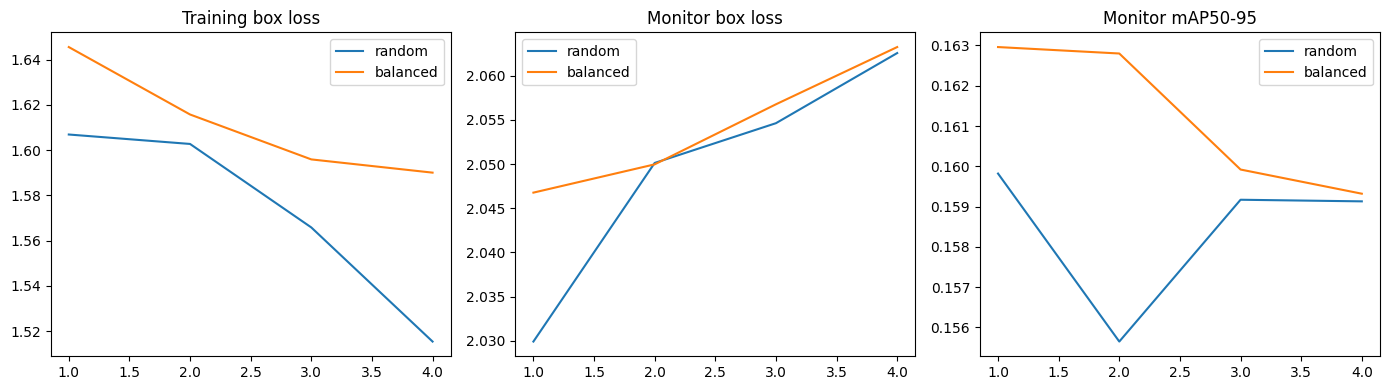

PILOT COMPLETE. Elapsed compute seconds: 393.9
# RoadScan sampling pilot

## Training cost

| arm      | freeze   |   epochs | completed   |   seconds |   trainable |   total |
|:---------|:---------|---------:|:------------|----------:|------------:|--------:|
| random   |          |        4 | True        |  132.338  |     9950960 | 9950960 |
| balanced |          |        4 | True        |   91.3481 |     9950960 | 9950960 |

## Development results

| arm       | domain        | completed   |    mAP50 |   mAP50_95 |   precision |   recall |
|:----------|:--------------|:------------|---------:|-----------:|------------:|---------:|
| unchanged | in_domain_dev | True        | 0.494317 |  0.229925  |    0.594249 | 0.466486 |
| unchanged | china_dev     | True        | 0.259186 |  0.106458  |    0.34068  | 0.309798 |
| random    | in_domain_dev | True        | 0.493349 |  0.227579  |    0.592305 | 0.469367 |
| random    | china_dev     | True        | 0.248706 |  0.0990211 |    0.31885

,arm,best_epoch,monitor_AP
0,random,1,0.15982
1,balanced,1,0.16296


FINAL PACKAGE VERIFIED. No training remains running.


In [5]:
saved=OUT/'candidates';saved.mkdir(exist_ok=True)
for name,checkpoint in candidates.items():shutil.copy2(checkpoint,saved/(name+'.pt'))
fig,axes=plt.subplots(1,3,figsize=(14,4))
for row in training_rows:
    h=pd.read_csv(OUT/'runs'/row['arm']/'results.csv');h.columns=h.columns.str.strip()
    axes[0].plot(h.epoch,h['train/box_loss'],label=row['arm']);axes[1].plot(h.epoch,h['val/box_loss'],label=row['arm']);axes[2].plot(h.epoch,h['metrics/mAP50-95(B)'],label=row['arm'])
for ax,title in zip(axes,['Training box loss','Monitor box loss','Monitor mAP50-95']):ax.set_title(title);ax.legend()
fig.tight_layout();fig.savefig(OUT/'pilot_curves.png',dpi=140);plt.show();plt.close(fig)
bundle=OUT/'model_bundle';bundle.mkdir(exist_ok=True);shutil.copy2(candidates[WINNER],bundle/'best.pt')
config=dict(classes=CLASSES,image_size=640,confidence=0.25,iou=0.7,max_det=300,rect=False,nms=True,arm=WINNER,threshold_note='Fixed diagnostic operating point; not a guaranteed deployment threshold.')
(bundle/'config.json').write_text(json.dumps(config,indent=2));(bundle/'requirements.txt').write_text('ultralytics==8.4.177\n')
(bundle/'predict.py').write_text("import argparse, json\nfrom pathlib import Path\nfrom ultralytics import YOLO\nparser=argparse.ArgumentParser()\nparser.add_argument('--image',required=True)\nparser.add_argument('--device',default='cpu')\nargs=parser.parse_args()\nroot=Path(__file__).resolve().parent\nc=json.loads((root/'config.json').read_text())\nmodel=YOLO(str(root/'best.pt'))\nmodel.predict(args.image,device=args.device,imgsz=c['image_size'],conf=c['confidence'],\n              iou=c['iou'],max_det=c['max_det'],rect=c['rect'],nms=c['nms'],save=True)\n")
check_code="from ultralytics import YOLO; m=YOLO("+repr(str(bundle/'best.pt'))+"); m.predict("+repr(str(tables['monitor'].iloc[0].path))+",device='cpu',imgsz=640,conf=.25,rect=False,nms=True,verbose=False); print('Fresh CPU load passed')"
fresh=subprocess.run([sys.executable,'-c',check_code],capture_output=True,text=True,timeout=180)
(OUT/'fresh_load.txt').write_text(fresh.stdout+fresh.stderr);assert fresh.returncode==0,fresh.stderr
report=['# RoadScan sampling pilot','## Training cost',pd.DataFrame(training_rows).to_markdown(index=False),'## Development results',results.to_markdown(index=False),'## Ranking',rank.to_markdown(),'Selected: '+WINNER,'## Interpretation','All arms share the starting checkpoint, sample size, augmentation, optimizer, seed and epoch budget. The monitor selects best checkpoints. Incomplete arms cannot win. The unchanged model is eligible.','This small single-seed pilot is development tuning, not proof of no overfitting or performance in Saudi Arabia. Test annotations were not opened. The 92% target is not guaranteed.','The two training policies differ in sample membership only. Fresh-process CPU inference passed.']
(OUT/'REPORT.md').write_text('\n\n'.join(report));(bundle/'MODEL_CARD.md').write_text('\n\n'.join(report))
(bundle/'SHA256.json').write_text(json.dumps({p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in bundle.iterdir() if p.is_file() and p.name!='SHA256.json'},indent=2))
shutil.make_archive('/kaggle/working/roadscan_balance_model','zip',root_dir=bundle)
print('PILOT COMPLETE. Elapsed compute seconds:',round(time.monotonic()-experiment_start,1),flush=True)
print('\n\n'.join(report))

selection=[]
for item in training_rows:
    history=pd.read_csv(OUT/'runs'/item['arm']/'results.csv');history.columns=history.columns.str.strip()
    best=history.loc[history['metrics/mAP50-95(B)'].idxmax()]
    selection.append(dict(arm=item['arm'],best_epoch=int(best.epoch),monitor_AP=float(best['metrics/mAP50-95(B)'])))
selection=pd.DataFrame(selection);selection.to_csv(OUT/'checkpoint_selection.csv',index=False);display(selection)
notes='This experiment changes a combined training sampling policy. Single-seed differences can be sampling noise. Falling training loss with worsening monitor loss/AP is a warning of overfitting. Best weights are selected by the monitor; the unchanged checkpoint is retained if it ranks first. Development sets have been reused; they are not blind tests. No test labels were opened. Local Saudi quality remains unmeasured.'
with (OUT/'REPORT.md').open('a') as file:file.write('\n\n'+support.to_markdown(index=False)+'\n\n'+selection.to_markdown(index=False)+'\n\n'+notes)
(bundle/'MODEL_CARD.md').write_text((OUT/'REPORT.md').read_text())
(bundle/'SHA256.json').write_text(json.dumps({p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in bundle.iterdir() if p.is_file() and p.name!='SHA256.json'},indent=2))
for name,digest in json.loads((bundle/'SHA256.json').read_text()).items():assert hashlib.sha256((bundle/name).read_bytes()).hexdigest()==digest
shutil.make_archive('/kaggle/working/roadscan_balance_model','zip',root_dir=bundle)
print('FINAL PACKAGE VERIFIED. No training remains running.')


## 6. Test one fixed road-region crop without retraining

The balanced sample slightly improved mAP50 but did not improve the declared worst-domain mAP50–95 criterion, so the previous checkpoint remains selected. Now isolate an inference-only hypothesis: combine a full-frame view with an extra view containing the lower 75% of the image. Map crop boxes back to original coordinates and keep ALL original annotations, including objects outside the crop. Compare full-frame and combined predictions using the same COCO evaluator and maximum 100 detections. These scores have a different evaluator/cap from section 4 and must be compared within this experiment only. The crop is fixed before this evaluation; do not search crop parameters. Stop this check after ten minutes. It cannot establish local-road quality or absence of overfitting.

In [6]:
# Compare full-frame inference with full-frame plus one fixed road-region crop.
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pycocotools'],check=True,timeout=120)
from PIL import Image
from torchvision.ops import batched_nms
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import contextlib, io
roi_dir=OUT/'localization_check';roi_dir.mkdir(exist_ok=True)
roi_start=time.monotonic();roi_deadline=roi_start+600
roi_model=YOLO(str(candidates[WINNER]))
roi_rows=[];roi_class_rows=[]
def merge_predictions(detections):
    boxes=torch.cat([d[0] for d in detections]);scores=torch.cat([d[1] for d in detections]);classes=torch.cat([d[2] for d in detections])
    keep=batched_nms(boxes,scores,classes,0.7)[:100]
    return boxes[keep],scores[keep],classes[keep]
for domain in ['in_domain_dev','china_dev']:
    ground_truth=dict(images=[],annotations=[],categories=[dict(id=i,name=name) for i,name in enumerate(CLASSES)],info={})
    predictions={'full_frame':[],'full_plus_crop':[]};annotation_id=1
    for image_id,row in enumerate(tables[domain].itertuples(),start=1):
        assert time.monotonic()<roi_deadline,'Localization check exceeded 10 minutes. Partial predictions are not eligible.'
        path=LOCAL/domain/'images'/Path(row.path).name
        rgb=np.asarray(Image.open(path).convert('RGB'));height,width=rgb.shape[:2]
        top=int(0.25*height)
        views=[rgb[:,:,::-1].copy(),rgb[top:,:,::-1].copy()]
        output=roi_model.predict(views,imgsz=640,rect=False,batch=2,device=0,conf=0.001,iou=0.7,max_det=300,nms=True,verbose=False)
        full=output[0].boxes;crop=output[1].boxes
        crop_boxes=crop.xyxy.clone();crop_boxes[:,[1,3]]+=top
        first=(full.xyxy,full.conf,full.cls.long());second=(crop_boxes,crop.conf,crop.cls.long())
        for mode,detections in [('full_frame',[first]),('full_plus_crop',[first,second])]:
            boxes,scores,classes=merge_predictions(detections)
            for box,score,cls in zip(boxes.cpu().tolist(),scores.cpu().tolist(),classes.cpu().tolist()):
                x1,y1,x2,y2=box
                predictions[mode].append(dict(image_id=image_id,category_id=int(cls),bbox=[x1,y1,x2-x1,y2-y1],score=score))
        ground_truth['images'].append(dict(id=image_id,width=width,height=height,file_name=path.name))
        for line in Path(row.label).read_text().splitlines():
            if not line.strip():continue
            cls,cx,cy,bw,bh=map(float,line.split());bw*=width;bh*=height
            ground_truth['annotations'].append(dict(id=annotation_id,image_id=image_id,category_id=int(cls),bbox=[cx*width-bw/2,cy*height-bh/2,bw,bh],area=bw*bh,iscrowd=0));annotation_id+=1
        if image_id%250==0:print(domain,image_id,'images processed',flush=True)
    (roi_dir/(domain+'_ground_truth.json')).write_text(json.dumps(ground_truth))
    coco=COCO();coco.dataset=ground_truth;coco.createIndex()
    for mode,records in predictions.items():
        (roi_dir/(domain+'_'+mode+'_predictions.json')).write_text(json.dumps(records))
        assert records,'No predictions produced; review before reporting metrics.'
        evaluator=COCOeval(coco,coco.loadRes(records),'bbox');evaluator.evaluate();evaluator.accumulate();evaluator.summarize()
        roi_rows.append(dict(domain=domain,mode=mode,AP50=float(evaluator.stats[1]),AP50_95=float(evaluator.stats[0])))
        precision=evaluator.eval['precision']
        for class_id,name in enumerate(CLASSES):
            values=precision[:,:,class_id,0,2];valid=values[values>=0]
            at50=precision[0,:,class_id,0,2];at50=at50[at50>=0]
            roi_class_rows.append(dict(domain=domain,mode=mode,class_name=name,AP50=float(at50.mean()) if len(at50) else None,AP50_95=float(valid.mean()) if len(valid) else None))
    pd.DataFrame(roi_rows).to_csv(roi_dir/'domain_results.csv',index=False)
    pd.DataFrame(roi_class_rows).to_csv(roi_dir/'class_results.csv',index=False)
roi_results=pd.DataFrame(roi_rows);display(roi_results)
roi_rank=roi_results.groupby('mode').agg(worst_domain_AP=('AP50_95','min'),mean_domain_AP=('AP50_95','mean')).sort_values(['worst_domain_AP','mean_domain_AP'],ascending=False)
display(roi_rank);roi_rank.to_csv(roi_dir/'ranking.csv')
roi_notes='The crop removes the top 25% of pixels in an additional view only. Full-frame predictions and ALL original ground-truth boxes remain in evaluation. Crop predictions are mapped back to original image coordinates, merged with class-aware NMS at IoU 0.70 and capped at 100 detections. Both arms use the same pycocotools COCO evaluator, maximum 100 detections, and 640 square inputs. These values use a different evaluator/cap from the earlier Ultralytics table; compare the two rows within this experiment only. The combined view costs extra inference. This is development tuning with a fixed crop, no training and no test use.'
(roi_dir/'REPORT.md').write_text('# Localization/crop check\n\n'+roi_results.to_markdown(index=False)+'\n\n'+roi_rank.to_markdown()+'\n\n'+roi_notes+'\n\nSeconds: '+str(round(time.monotonic()-roi_start,1)))
print(roi_notes)
print('LOCALIZATION CHECK COMPLETE. Seconds:',round(time.monotonic()-roi_start,1))
del roi_model;gc.collect();torch.cuda.empty_cache()


in_domain_dev 250 images processed
in_domain_dev 500 images processed
in_domain_dev 750 images processed
in_domain_dev 1000 images processed
creating index...
index created!
Loading and preparing results...
DONE (t=0.04s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=1.66s).
Accumulating evaluation results...
DONE (t=0.38s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.232
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.493
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.172
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.151
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.186
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.282
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.251
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   al

,domain,mode,AP50,AP50_95
0,in_domain_dev,full_frame,0.493188,0.231534
1,in_domain_dev,full_plus_crop,0.497771,0.235162
2,china_dev,full_frame,0.261108,0.108815
3,china_dev,full_plus_crop,0.260227,0.109220


,worst_domain_AP,mean_domain_AP
mode,,
full_plus_crop,0.109220,0.172191
full_frame,0.108815,0.170174


The crop removes the top 25% of pixels in an additional view only. Full-frame predictions and ALL original ground-truth boxes remain in evaluation. Crop predictions are mapped back to original image coordinates, merged with class-aware NMS at IoU 0.70 and capped at 100 detections. Both arms use the same pycocotools COCO evaluator, maximum 100 detections, and 640 square inputs. These values use a different evaluator/cap from the earlier Ultralytics table; compare the two rows within this experiment only. The combined view costs extra inference. This is development tuning with a fixed crop, no training and no test use.
LOCALIZATION CHECK COMPLETE. Seconds: 109.7


## 7. Record the decision and verify the final package

Keep the previously selected checkpoint: the balanced policy did not improve the declared worst-domain mAP50–95 criterion. The fixed extra crop produced only a negligible worst-domain gain with an extra inference view, so full-frame inference remains the practical default. Record both experiments, their different evaluation protocols, early overfitting warnings, timings and limitations. Verify that the packaged weights exactly match the retained checkpoint. Save notebook outputs before stopping the GPU session; do not launch another training extension.

In [7]:
summary = '''# Final review: sampling and localization pilots

## Training sample comparison
Both arms used 1,200 unique images, four epochs and the same starting checkpoint, optimizer, augmentation and development monitor. The random arm contained 581 backgrounds; the combined background/class-aware policy contained 240. This policy is a combined intervention; individual causes cannot be separated.

The balanced arm improved development mAP50 from 49.4317% to 49.9335% in-domain and from 25.9186% to 26.4837% in China. Its worst-domain mAP50-95 was 10.6223%, slightly below the unchanged checkpoint at 10.6458%. The declared criterion therefore retains the unchanged notebook 10 checkpoint. Random continuation also did not beat it. This small pilot does not establish that balancing never helps.

## Fixed crop experiment
The same retained weights were evaluated with full-frame inference and full-frame plus one fixed lower-75% crop. All original annotations remained in evaluation. On the paired COCO protocol, mAP50-95 changed from 23.1534% to 23.5162% in-domain and from 10.8815% to 10.9220% in China. China mAP50 decreased slightly from 26.1108% to 26.0227%.

The extra view gives only a 0.0405 percentage-point improvement in worst-domain mAP50-95, while requiring an additional inference view. Retain full-frame inference as the practical default. Keep the two-view result as an experimental alternative, not a claimed major improvement. The COCO protocol uses 100 detections and differs from the 300-detection Ultralytics protocol above; compare modes within each protocol only.

## Overfitting and evaluation limits
Training losses decrease while monitor AP peaks early and then declines in both arms. This is a short-run overfitting warning. Best-monitor checkpoint selection limits the observed damage, but does not establish zero overfitting. The authoritative history contains four training epochs per arm; a final validation callback may print epoch five without training another epoch.

These are single-seed, development-selected results. No test labels were opened in this notebook. Development sets have been reused, so the results are not blind-test estimates. No annotated Saudi-road set has been evaluated. Neither 92% nor 97% performance has been achieved or guaranteed.

## Decision
Keep notebook 10 selected checkpoint with full-frame 640-square inference. Do not extend training automatically. The next useful evidence is an independently annotated local-road set and a focused expert review of crack boxes and scarce pothole examples. Preserve a local blind test separately before using other local images for adaptation. More training alone has not solved the observed domain gap.
'''
print(summary)
display(results)
display(roi_results)
display(selection)
(OUT/'FINAL_REVIEW.md').write_text(summary)
with (OUT/'REPORT.md').open('a') as file:file.write('\n\n'+summary)
(bundle/'MODEL_CARD.md').write_text((OUT/'REPORT.md').read_text())
config=json.loads((bundle/'config.json').read_text())
config.update(inference_policy='full_frame',crop_policy_note='Extra fixed crop tested; negligible worst-domain gain, extra inference cost. Experimental results saved separately.')
(bundle/'config.json').write_text(json.dumps(config,indent=2))
(bundle/'SHA256.json').write_text(json.dumps({p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in bundle.iterdir() if p.is_file() and p.name!='SHA256.json'},indent=2))
for name,digest in json.loads((bundle/'SHA256.json').read_text()).items():assert hashlib.sha256((bundle/name).read_bytes()).hexdigest()==digest
assert hashlib.sha256((bundle/'best.pt').read_bytes()).hexdigest()==plan['start_sha256']
shutil.make_archive('/kaggle/working/roadscan_balance_model','zip',root_dir=bundle)
print('Selected checkpoint identity and package hashes verified.')
print('Training seconds:',pd.DataFrame(training_rows).seconds.sum())
print('Crop check seconds:',round(time.monotonic()-roi_start,1),'including interactive review time after computation; actual computation recorded in localization_check/REPORT.md.')
print('FINAL OUTPUTS COMPLETE. No training or evaluation remains running. Save outputs, verify the saved version, then stop the interactive session.')


# Final review: sampling and localization pilots

## Training sample comparison
Both arms used 1,200 unique images, four epochs and the same starting checkpoint, optimizer, augmentation and development monitor. The random arm contained 581 backgrounds; the combined background/class-aware policy contained 240. This policy is a combined intervention; individual causes cannot be separated.

The balanced arm improved development mAP50 from 49.4317% to 49.9335% in-domain and from 25.9186% to 26.4837% in China. Its worst-domain mAP50-95 was 10.6223%, slightly below the unchanged checkpoint at 10.6458%. The declared criterion therefore retains the unchanged notebook 10 checkpoint. Random continuation also did not beat it. This small pilot does not establish that balancing never helps.

## Fixed crop experiment
The same retained weights were evaluated with full-frame inference and full-frame plus one fixed lower-75% crop. All original annotations remained in evaluation. On the paired COCO prot

,arm,domain,completed,mAP50,mAP50_95,precision,recall
0,unchanged,in_domain_dev,True,0.494317,0.229925,0.594249,0.466486
1,unchanged,china_dev,True,0.259186,0.106458,0.340680,0.309798
2,random,in_domain_dev,True,0.493349,0.227579,0.592305,0.469367
3,random,china_dev,True,0.248706,0.099021,0.318855,0.316068
4,balanced,in_domain_dev,True,0.499335,0.229618,0.578580,0.484090
5,balanced,china_dev,True,0.264837,0.106223,0.337573,0.334050


,domain,mode,AP50,AP50_95
0,in_domain_dev,full_frame,0.493188,0.231534
1,in_domain_dev,full_plus_crop,0.497771,0.235162
2,china_dev,full_frame,0.261108,0.108815
3,china_dev,full_plus_crop,0.260227,0.109220


,arm,best_epoch,monitor_AP
0,random,1,0.15982
1,balanced,1,0.16296


Selected checkpoint identity and package hashes verified.
Training seconds: 223.68591497399996
Crop check seconds: 179.2 including interactive review time after computation; actual computation recorded in localization_check/REPORT.md.
FINAL OUTPUTS COMPLETE. No training or evaluation remains running. Save outputs, verify the saved version, then stop the interactive session.
